<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook8_Ridge_Lasso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.dummy import DummyRegressor

train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Train:", train.shape, "| features all:", X_all.shape[1], "| early:", X_early.shape[1])

Train: (285, 42) | features all: 41 | early: 39


In [3]:
# Cell 2: measure multicollinearity with VIF
def vif_table(X):
    Xs = StandardScaler().fit_transform(X)
    out = {}
    for i, c in enumerate(X.columns):
        others = np.delete(Xs, i, axis=1)
        r2 = LinearRegression().fit(others, Xs[:, i]).score(others, Xs[:, i])
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out).sort_values(ascending=False)

vif = vif_table(X_all)
print("Highest VIF scores:")
print(vif.head(8).round(2))
print("\nCorrelation between G1 and G2:", round(X_all["G1"].corr(X_all["G2"]), 3))

Highest VIF scores:
G2               7.55
G1               7.45
Fjob_other       5.73
Fjob_services    4.99
Mjob_services    3.19
Mjob_teacher     3.17
Mjob_other       3.08
Medu             2.96
dtype: float64

Correlation between G1 and G2: 0.901


           G1            G2       
         mean    std   mean    std
model                             
Linear  0.371  0.150  2.798  0.171
Ridge   0.988  0.082  1.904  0.072

Linear: correlation between the G1 and G2 weights across resamples:
      G1    G2
G1  1.00 -0.69
G2 -0.69  1.00


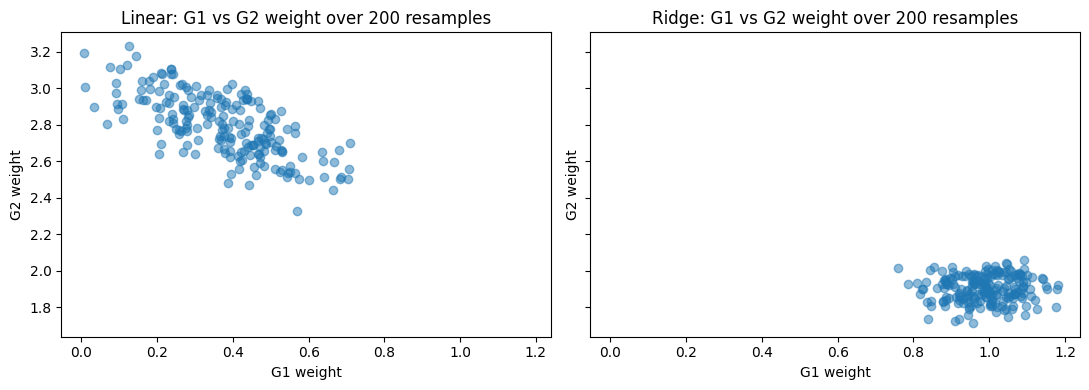

In [4]:
# Cell 3: the instability, shown by refitting on 200 resampled versions of the data
rng = np.random.default_rng(0)
cols = list(X_all.columns)
i1, i2 = cols.index("G1"), cols.index("G2")

rows = []
for _ in range(200):
    idx = rng.integers(0, len(X_all), len(X_all))     # resample with replacement
    Xb, yb = X_all.iloc[idx], y.iloc[idx]
    for name, mdl in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=30))]:
        coef = make_pipeline(StandardScaler(), mdl).fit(Xb, yb)[-1].coef_
        rows.append({"model": name, "G1": coef[i1], "G2": coef[i2]})
boot = pd.DataFrame(rows)

print(boot.groupby("model")[["G1", "G2"]].agg(["mean", "std"]).round(3))
print("\nLinear: correlation between the G1 and G2 weights across resamples:")
print(boot[boot.model == "Linear"][["G1", "G2"]].corr().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["Linear", "Ridge"]):
    b = boot[boot.model == name]
    ax.scatter(b["G1"], b["G2"], alpha=0.5)
    ax.set_title(f"{name}: G1 vs G2 weight over 200 resamples")
    ax.set_xlabel("G1 weight"); ax.set_ylabel("G2 weight")
plt.tight_layout()
plt.savefig("weights_stability.png", dpi=150, bbox_inches="tight")
plt.show()

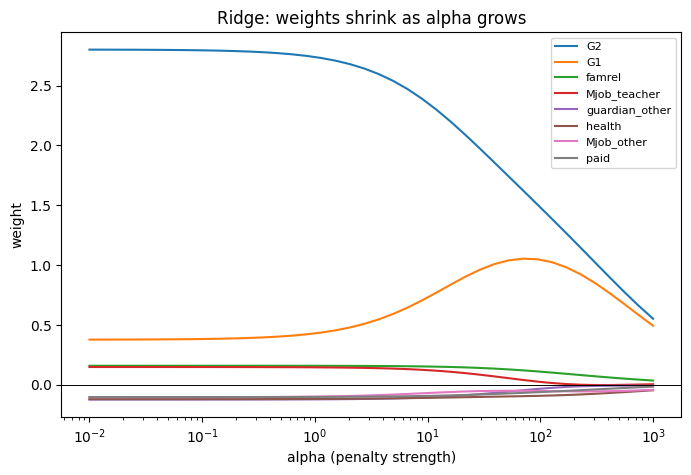

In [5]:
# Cell 4: Ridge coefficient path, what happens as alpha grows
scaler = StandardScaler().fit(X_all)          # exploration on training data only
Xs = scaler.transform(X_all)

alphas = np.logspace(-2, 3, 40)
paths = np.array([Ridge(alpha=a).fit(Xs, y).coef_ for a in alphas])
top = np.argsort(-np.abs(paths[0]))[:8]

plt.figure(figsize=(8, 5))
for j in top:
    plt.plot(alphas, paths[:, j], label=X_all.columns[j])
plt.xscale("log"); plt.axhline(0, color="black", linewidth=0.7)
plt.xlabel("alpha (penalty strength)"); plt.ylabel("weight")
plt.title("Ridge: weights shrink as alpha grows")
plt.legend(fontsize=8)
plt.savefig("ridge_path.png", dpi=150, bbox_inches="tight")
plt.show()

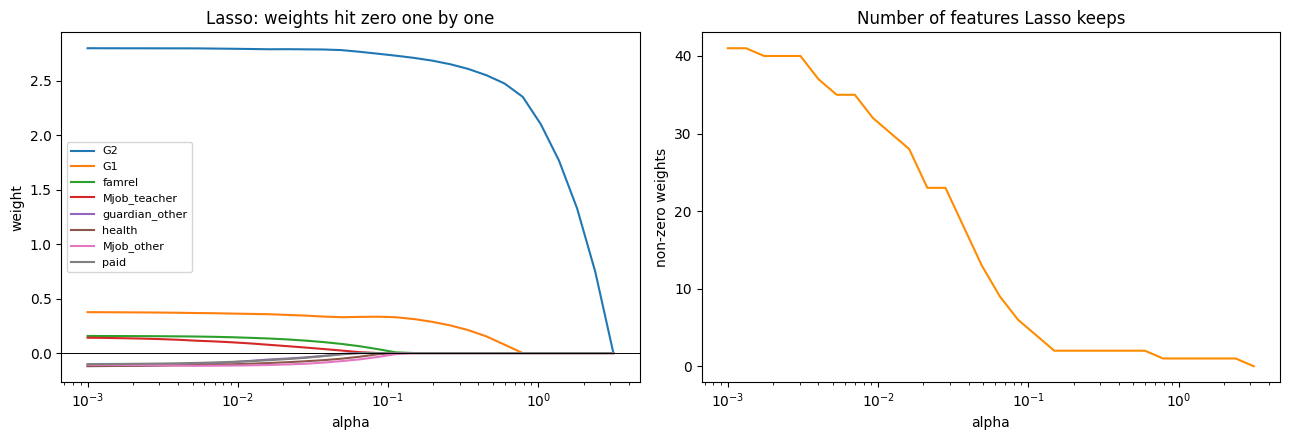

In [6]:
# Cell 5: Lasso path, weights reach exactly zero
lasso_alphas = np.logspace(-3, 0.5, 30)
lpaths, n_nonzero = [], []
for a in lasso_alphas:
    c = Lasso(alpha=a, max_iter=20000).fit(Xs, y).coef_
    lpaths.append(c)
    n_nonzero.append((c != 0).sum())
lpaths = np.array(lpaths)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for j in top:
    axes[0].plot(lasso_alphas, lpaths[:, j], label=X_all.columns[j])
axes[0].set_xscale("log"); axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Lasso: weights hit zero one by one")
axes[0].set_xlabel("alpha"); axes[0].set_ylabel("weight"); axes[0].legend(fontsize=8)

axes[1].plot(lasso_alphas, n_nonzero, color="darkorange")
axes[1].set_xscale("log")
axes[1].set_title("Number of features Lasso keeps")
axes[1].set_xlabel("alpha"); axes[1].set_ylabel("non-zero weights")
plt.tight_layout()
plt.savefig("lasso_path.png", dpi=150, bbox_inches="tight")
plt.show()

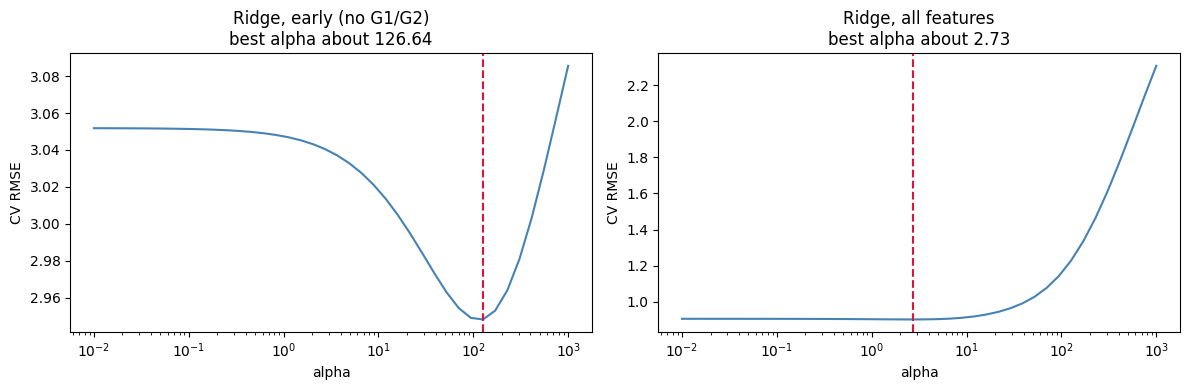

In [7]:
# Cell 6: choosing alpha, CV error across alpha values, for both feature sets
cv_curves = {}
for name, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    errs = []
    for a in alphas:
        s = -cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)),
                             X, y, cv=cv, scoring="neg_root_mean_squared_error")
        errs.append(s.mean())
    cv_curves[name] = errs

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, errs) in zip(axes, cv_curves.items()):
    ax.plot(alphas, errs, color="steelblue")
    best = alphas[int(np.argmin(errs))]
    ax.axvline(best, color="crimson", linestyle="--")
    ax.set_xscale("log")
    ax.set_title(f"Ridge, {name}\nbest alpha about {best:.2f}")
    ax.set_xlabel("alpha"); ax.set_ylabel("CV RMSE")
plt.tight_layout()
plt.savefig("ridge_alpha_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Cell 7: fair comparison. RidgeCV and LassoCV pick alpha INSIDE each training fold,
# so the score is not flattered by the tuning.
models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge (CV alpha)": make_pipeline(StandardScaler(),
                                      RidgeCV(alphas=np.logspace(-2, 3, 40))),
    "Lasso (CV alpha)": make_pipeline(StandardScaler(),
                                      LassoCV(alphas=np.logspace(-3, 0.5, 30), cv=5, max_iter=20000)),
}

rows = []
for fname, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    for mname, m in models.items():
        s = -cross_val_score(m, X, y, cv=cv, scoring="neg_root_mean_squared_error")
        rows.append({"features": fname, "model": mname,
                     "CV RMSE": round(s.mean(), 3), "std": round(s.std(), 3)})
results = pd.DataFrame(rows)
results.pivot(index="model", columns="features", values="CV RMSE")

features,all features,early (no G1/G2)
model,,
Baseline (mean),3.255,3.255
Lasso (CV alpha),0.841,2.951
Linear,0.906,3.052
Ridge (CV alpha),0.903,2.961


In [9]:
# Cell 8: which features does Lasso keep? (fit on all training data)
for fname, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    lasso = make_pipeline(StandardScaler(),
                          LassoCV(alphas=np.logspace(-3, 0.5, 30), cv=5, max_iter=20000)).fit(X, y)
    coef = pd.Series(lasso[-1].coef_, index=X.columns)
    kept = coef[coef != 0].sort_values(key=abs, ascending=False)
    print(f"\n{fname}: alpha = {lasso[-1].alpha_:.3f}, kept {len(kept)} of {X.shape[1]} features")
    print(kept.round(3).head(10).to_string())


early (no G1/G2): alpha = 0.149, kept 20 of 39 features
schoolsup       -0.682
failures        -0.576
absences        -0.465
Mjob_services    0.438
Fjob_teacher     0.301
internet         0.276
goout           -0.225
famsup          -0.212
Mjob_health      0.200
Walc            -0.186

all features: alpha = 0.085, kept 6 of 41 features
G2            2.750
G1            0.334
Mjob_other   -0.036
famrel        0.036
health       -0.011
goout        -0.010


In [10]:
# Cell 9: reading the weights in real units (early model, Ridge)
ridge_early = make_pipeline(StandardScaler(),
                            RidgeCV(alphas=np.logspace(-2, 3, 40))).fit(X_early, y)
sc = ridge_early[0]
per_unit = pd.Series(ridge_early[-1].coef_ / sc.scale_, index=X_early.columns)

print("Change in predicted G3 for a 1-unit increase (other features held fixed):")
for c in ["failures", "studytime", "absences", "age", "higher", "Medu", "goout"]:
    print(f"  {c:10s} {per_unit[c]:+.3f}")

Change in predicted G3 for a 1-unit increase (other features held fixed):
  failures   -0.680
  studytime  +0.302
  absences   -0.076
  age        -0.110
  higher     +0.528
  Medu       +0.119
  goout      -0.257


In [11]:
# Cell 10: save the results table, used again on Day 16
results.to_csv("results_linear.csv", index=False)
print(results.to_string(index=False))

        features            model  CV RMSE   std
early (no G1/G2)  Baseline (mean)    3.255 0.125
early (no G1/G2)           Linear    3.052 0.169
early (no G1/G2) Ridge (CV alpha)    2.961 0.086
early (no G1/G2) Lasso (CV alpha)    2.951 0.149
    all features  Baseline (mean)    3.255 0.125
    all features           Linear    0.906 0.079
    all features Ridge (CV alpha)    0.903 0.076
    all features Lasso (CV alpha)    0.841 0.037
